# 08 — Regression: Predicting Delivery Time at Checkout

## Business problem
Customers see a delivery **promise** at checkout. Phase 8 showed that the promise is very conservative (median 12 days early), and that missing it is the strongest driver of bad reviews. Two business questions follow:
1. **How long will this order actually take?** A realistic estimate.
2. **How short could the promise be** while keeping lateness at an acceptable level?

## Definitions
- **Target:** `delivery_days`, the actual time from purchase to delivery (Gold `purchase_to_delivery_days`, D-08 guarded).
- **Population:** D-06 eligible orders (delivered, with a delivery date) with items, purchased in the Q-11 window 2017-01 to 2018-08.
- **Prediction moment:** the customer places the order. Features use only information available then (`src/ml/delivery_features.py`):
  - the promise shown at checkout;
  - the basket, price, freight and payment;
  - customer and main-seller location and their distance;
  - product weight, volume and category;
  - purchase date and time.
- **Excluded as leakage:** approval, carrier and delivery timestamps, all durations, the final order status, reviews, and post-purchase quality flags.

## Validation design
- **Temporal split.** The test set is the **most recent four months (2018-05 to 2018-08)**, used once at the end. Development covers 2017-01 to 2018-04. A random split would let the model learn from the future and would hide the strong drift in delivery times.
- **Tuning:** `TimeSeriesSplit` (4 expanding-window folds) inside the development period.
- **Preprocessing** (imputation, scaling, encoding) lives inside scikit-learn pipelines, so it's fitted on training folds only.
- **Seed** 42 everywhere.
- **Metrics:**
  - **MAE**, in days, is the primary metric: it's the customer-facing error, and it's robust to the long tail.
  - **RMSE** penalises large misses.
  - **R²** shows the variance explained relative to predicting the mean.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.ml.delivery_features import CATEGORICAL, FEATURES, LEAKAGE_COLUMNS, NUMERIC, build_dataset, temporal_split

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = 42
FIG = ROOT / "reports" / "machine_learning" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

data = build_dataset()
dev, test = temporal_split(data, "2018-05-01")
X_dev, y_dev, X_test, y_test = dev[FEATURES], dev["delivery_days"], test[FEATURES], test["delivery_days"]
cv = TimeSeriesSplit(n_splits=4)

# validation: grain, leakage, split, target construction
orders = pd.read_parquet(ROOT / "data" / "processed" / "analytical" / "fact_orders.parquet").set_index("order_id")
recomputed = (orders.loc[data["order_id"], "order_delivered_customer_date"] - orders.loc[data["order_id"], "order_purchase_timestamp"]).dt.total_seconds() / 86400
assert data["order_id"].is_unique and not (set(FEATURES) & LEAKAGE_COLUMNS)
assert dev["purchase_ts"].max() < test["purchase_ts"].min() and dev["purchase_ts"].is_monotonic_increasing
assert np.allclose(recomputed.to_numpy(), data["delivery_days"].to_numpy())
print(f"orders {len(data):,} | development {len(dev):,} ({dev['purchase_ts'].min():%Y-%m} to {dev['purchase_ts'].max():%Y-%m}) | "
      f"test {len(test):,} ({test['purchase_ts'].min():%Y-%m} to {test['purchase_ts'].max():%Y-%m})")
print(f"delivery days: development median {y_dev.median():.1f}, mean {y_dev.mean():.1f} | test median {y_test.median():.1f}, mean {y_test.mean():.1f}")
print("TimeSeriesSplit folds (train -> validation months):",
      [f"{dev['purchase_ts'].iloc[tr[-1]]:%Y-%m} -> {dev['purchase_ts'].iloc[va[0]]:%Y-%m}..{dev['purchase_ts'].iloc[va[-1]]:%Y-%m}" for tr, va in cv.split(X_dev)])

orders 96,203 | development 70,851 (2017-01 to 2018-04) | test 25,352 (2018-05 to 2018-08)
delivery days: development median 11.3, mean 13.7 | test median 7.8, mean 9.4
TimeSeriesSplit folds (train -> validation months): ['2017-07 -> 2017-07..2017-10', '2017-10 -> 2017-10..2017-12', '2017-12 -> 2017-12..2018-02', '2018-02 -> 2018-02..2018-04']


## 1. Target and feature exploration (development data only)

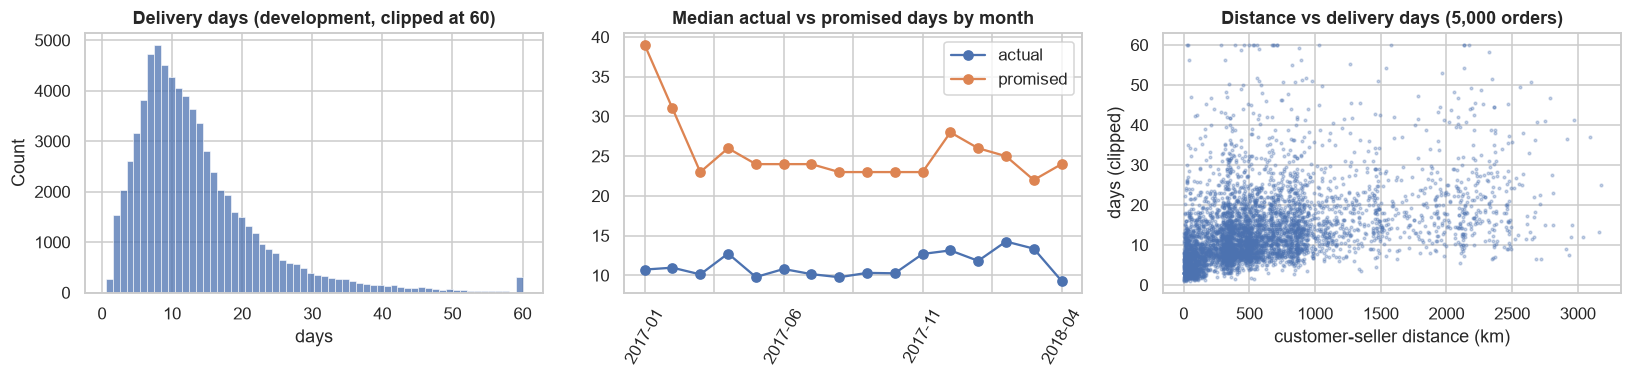

Spearman correlation with delivery days (development):


distance_km           0.540
promised_days         0.502
items_freight_total   0.409
customer_lat          0.262
freight_share         0.132
seller_lat            0.101
customer_lng          0.096
items_price_total     0.092


In [2]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
sns.histplot(y_dev.clip(upper=60), bins=60, ax=ax[0]); ax[0].set(title="Delivery days (development, clipped at 60)", xlabel="days")
m = dev.groupby(dev["purchase_ts"].dt.to_period("M").astype(str)).agg(actual=("delivery_days", "median"), promised=("promised_days", "median"))
m.plot(ax=ax[1], marker="o"); ax[1].set(title="Median actual vs promised days by month", xlabel=""); ax[1].tick_params(axis="x", rotation=60)
sample = dev.sample(5000, random_state=SEED)
ax[2].scatter(sample["distance_km"], sample["delivery_days"].clip(upper=60), s=3, alpha=.3)
ax[2].set(title="Distance vs delivery days (5,000 orders)", xlabel="customer-seller distance (km)", ylabel="days (clipped)")
plt.tight_layout(); plt.show()
print("Spearman correlation with delivery days (development):")
print(dev[NUMERIC + ["delivery_days"]].corr(method="spearman")["delivery_days"].drop("delivery_days").sort_values(key=abs, ascending=False).round(3).head(8).to_string())

**Interpretation.**
- **The target is right-skewed:** in development the median delivery time is 11.3 days and the mean 13.7, with a long tail of slow deliveries.
- **Delivery times fell sharply in 2018:** the test period has a median of 7.8 days and a mean of 9.4. A model trained on earlier months is therefore expected to over-predict somewhat in the test period.
- **Strongest monotonic relationships with delivery time** (Spearman, development data):
  - customer–seller **distance** (0.54);
  - the **promised days** (0.50), since Olist's promise already encodes route information;
  - **freight** (0.41), which grows with distance and weight;
  - **customer latitude** (0.26), i.e. how far north the customer is.
- **The monthly chart:** the promise sits far above actual delivery times in every month, which is the conservative promise Phase 8 identified.

## 2. Models
**Preprocessing:**
- **Linear model:** median imputation and scaling for numeric features; one-hot encoding for categoricals, with rare levels (< 100 orders) grouped.
- **Tree ensembles:** one-hot without scaling (random forest), or ordinal codes with native categorical and missing-value support (HistGradientBoosting).

**Baselines:** the development median (`DummyRegressor`), and **Olist's own promise** used as an estimate (`promised_days`).

**Tuning:** hyperparameters for the tree models are tuned on time-series CV, with MAE as the objective.

In [3]:
def linear_pre():
    return ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC),
                              ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False), CATEGORICAL)])

def onehot_pre():
    return ColumnTransformer([("num", SimpleImputer(strategy="median"), NUMERIC),
                              ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False), CATEGORICAL)])

def native_pre():   # HistGradientBoosting: NaN handled natively, categoricals as ordinal codes (unknown -> missing)
    return ColumnTransformer([("num", "passthrough", NUMERIC),
                              ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), CATEGORICAL)])
CAT_IDX = list(range(len(NUMERIC), len(NUMERIC) + len(CATEGORICAL)))

searches = {
    "Decision tree": GridSearchCV(make_pipeline(onehot_pre(), DecisionTreeRegressor(random_state=SEED)),
                                  {"decisiontreeregressor__max_depth": [6, 10, 14], "decisiontreeregressor__min_samples_leaf": [20, 100]},
                                  cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1),
    "Random forest": GridSearchCV(make_pipeline(onehot_pre(), RandomForestRegressor(n_estimators=200, max_features=0.3, random_state=SEED, n_jobs=-1)),
                                  {"randomforestregressor__min_samples_leaf": [5, 20], "randomforestregressor__max_depth": [None, 20]},
                                  cv=cv, scoring="neg_mean_absolute_error"),
    "HistGradientBoosting": RandomizedSearchCV(
        make_pipeline(native_pre(), HistGradientBoostingRegressor(categorical_features=CAT_IDX, random_state=SEED)),
        {"histgradientboostingregressor__learning_rate": [0.03, 0.06, 0.1], "histgradientboostingregressor__max_leaf_nodes": [15, 31, 63],
         "histgradientboostingregressor__min_samples_leaf": [20, 100], "histgradientboostingregressor__l2_regularization": [0.0, 1.0],
         "histgradientboostingregressor__loss": ["squared_error", "absolute_error"], "histgradientboostingregressor__max_iter": [300]},
        n_iter=10, cv=cv, scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=-1),
}
best = {}
for name, s in searches.items():
    s.fit(X_dev, y_dev)
    best[name] = s.best_estimator_
    print(f"{name}: CV MAE {-s.best_score_:.3f} | best params {{{', '.join(f'{k.split('__')[1]}: {v}' for k, v in s.best_params_.items())}}}")

Decision tree: CV MAE 5.601 | best params {max_depth: 6, min_samples_leaf: 20}


Random forest: CV MAE 5.376 | best params {max_depth: 20, min_samples_leaf: 20}


HistGradientBoosting: CV MAE 5.377 | best params {min_samples_leaf: 20, max_leaf_nodes: 15, max_iter: 300, loss: squared_error, learning_rate: 0.06, l2_regularization: 0.0}


,train MAE,CV MAE,CV MAE sd,test MAE,test RMSE,test R2
model,,,,,,
HistGradientBoosting,4.456,5.377,0.761,4.221,5.842,0.215
Random forest,4.227,5.376,0.793,4.365,5.923,0.193
Decision tree,4.885,5.601,0.811,4.410,6.011,0.169
Linear regression,4.867,5.499,0.822,5.149,6.659,-0.020
Baseline: development median,5.729,6.768,1.020,5.283,6.869,-0.086
Baseline: Olist promise,NaN,NaN,NaN,13.225,15.835,-4.769


model selected on cross-validation: Random forest


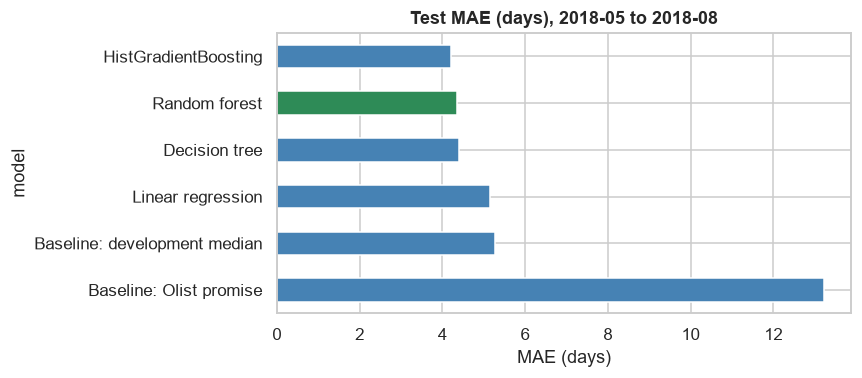

In [4]:
models = {"Baseline: development median": DummyRegressor(strategy="median"),
          "Linear regression": make_pipeline(linear_pre(), LinearRegression()), **best}

rows, preds = [], {}
def scores(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** .5, "R2": r2_score(y, p)}
for name, model in models.items():
    cvr = cross_validate(model, X_dev, y_dev, cv=cv, scoring="neg_mean_absolute_error", return_train_score=True)
    model.fit(X_dev, y_dev)
    preds[name] = model.predict(X_test)
    rows.append({"model": name, "train MAE": -cvr["train_score"].mean(), "CV MAE": -cvr["test_score"].mean(),
                 "CV MAE sd": cvr["test_score"].std(), **{f"test {k}": v for k, v in scores(y_test, preds[name]).items()}})
preds["Baseline: Olist promise"] = test["promised_days"].to_numpy(dtype=float)
rows.append({"model": "Baseline: Olist promise", **{f"test {k}": v for k, v in scores(y_test, preds["Baseline: Olist promise"]).items()}})
results = pd.DataFrame(rows).set_index("model").sort_values("test MAE")
display(results)
BEST = results.drop(index=[i for i in results.index if i.startswith("Baseline")])["CV MAE"].idxmin()   # chosen on CV, not on test
print(f"model selected on cross-validation: {BEST}")

fig, ax = plt.subplots(figsize=(8, 3.6))
results["test MAE"].sort_values().plot.barh(ax=ax, color=["seagreen" if i == BEST else "steelblue" for i in results["test MAE"].sort_values().index])
ax.set(title="Test MAE (days), 2018-05 to 2018-08", xlabel="MAE (days)"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(FIG / "regression_models.png", bbox_inches="tight"); plt.show()

**Interpretation of the model comparison.**
- **Selection:** the **random forest is selected on cross-validation** (CV MAE 5.376 days), essentially tied with HistGradientBoosting (5.377). The rule was fixed in advance: choose by CV, never by test. HistGradientBoosting happens to be slightly better on the test period (MAE 4.22, R² 0.22), but switching now would be test-set selection, so the gap is reported, not acted on.
- **Random forest vs the median baseline:** test MAE **4.37 days vs 5.28**, a **17% reduction** in the average error. RMSE falls from 6.87 to 5.92 and R² rises from −0.09 to 0.19. Checkout information gives real but limited predictive power: the model explains about a fifth of the variance in delivery time.
- **Linear regression** (MAE 5.15, R² −0.02) is barely better than the median. The relationships are non-linear and interact (distance × region × promise), which tree ensembles capture and a linear model doesn't.
- **Olist's promise used as an estimate** has an MAE of 13.2 days and R² −4.8. That is expected and isn't a model failure: the promise is a deliberately padded commitment, not an estimate of delivery time.
- **Generalisation:**
  - The random forest's train MAE (4.23) is below its CV MAE (5.38), so it fits the training months more closely than unseen ones.
  - The test MAE (4.37) is *lower* than the CV MAE. That's because the test months have shorter, less variable deliveries, not because the model got better.
  - The CV standard deviation (about 0.8 days) shows how strongly performance depends on the period.

## 3. Residual and error analysis (selected model, test period)

,orders,mean_residual,MAE
actual_bucket,,,
<=5,5637,-3.836,3.843
5-10,11184,-3.827,4.149
10-15,4898,-1.574,3.339
15-20,1983,2.531,4.058
20-30,1292,7.566,7.805
>30,358,22.664,22.664


,orders,mean_residual,MAE
purchase_ts,,,
2018-05,6749,0.014,4.591
2018-06,6096,-3.013,4.615
2018-07,6156,-2.412,4.431
2018-08,6351,-2.535,3.821


highest MAE states (>= 300 test orders): {'PE': 7.98, 'BA': 6.94, 'RJ': 5.75, 'ES': 5.53} | lowest: {'SP': 3.26, 'PR': 4.16, 'GO': 4.47}
median absolute error 3.62 days | share within 3 days 41.2% | share under-predicted by > 7 days 5.6%


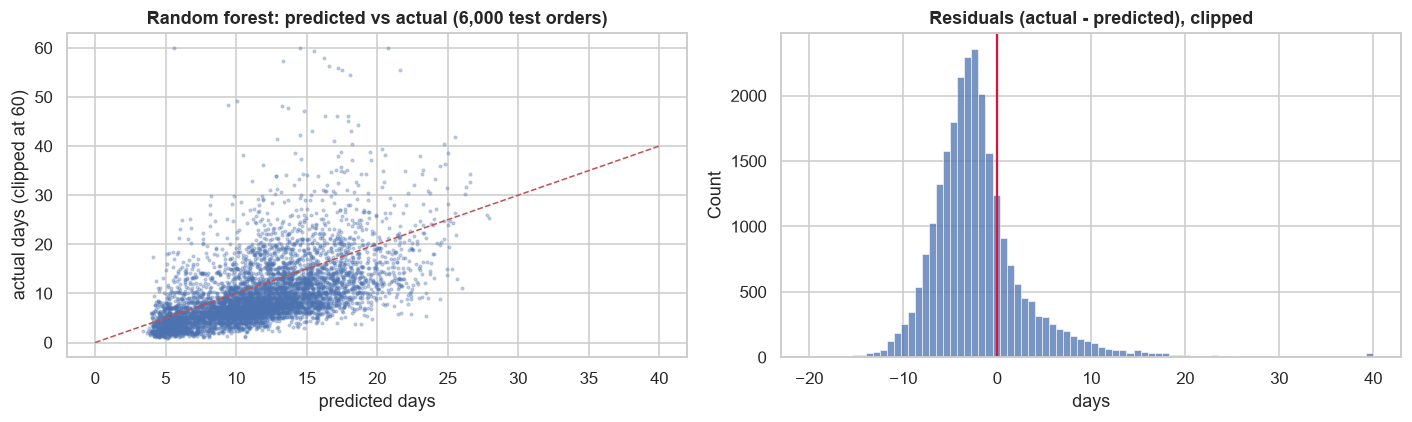

In [5]:
res = test.assign(pred=preds[BEST], resid=y_test - preds[BEST])
res["actual_bucket"] = pd.cut(res["delivery_days"], [0, 5, 10, 15, 20, 30, 300], labels=["<=5", "5-10", "10-15", "15-20", "20-30", ">30"])
by_bucket = res.groupby("actual_bucket", observed=True).agg(orders=("resid", "size"), mean_residual=("resid", "mean"),
                                                            MAE=("resid", lambda r: r.abs().mean()))
by_month = res.groupby(res["purchase_ts"].dt.to_period("M").astype(str)).agg(orders=("resid", "size"), mean_residual=("resid", "mean"),
                                                                             MAE=("resid", lambda r: r.abs().mean()))
by_state = res.groupby("customer_state").agg(orders=("resid", "size"), MAE=("resid", lambda r: r.abs().mean())).query("orders >= 300")
display(by_bucket); display(by_month)
print("highest MAE states (>= 300 test orders):", by_state.sort_values("MAE", ascending=False).head(4)["MAE"].round(2).to_dict(),
      "| lowest:", by_state.sort_values("MAE").head(3)["MAE"].round(2).to_dict())
print(f"median absolute error {res['resid'].abs().median():.2f} days | share within 3 days {(res['resid'].abs() <= 3).mean():.1%} | "
      f"share under-predicted by > 7 days {(res['resid'] > 7).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
s = res.sample(6000, random_state=SEED)
ax[0].scatter(s["pred"], s["delivery_days"].clip(upper=60), s=3, alpha=.3); ax[0].plot([0, 40], [0, 40], "r--", lw=1)
ax[0].set(title=f"{BEST}: predicted vs actual (6,000 test orders)", xlabel="predicted days", ylabel="actual days (clipped at 60)")
sns.histplot(res["resid"].clip(-20, 40), bins=80, ax=ax[1]); ax[1].axvline(0, color="crimson")
ax[1].set(title="Residuals (actual - predicted), clipped", xlabel="days")
plt.tight_layout(); plt.savefig(FIG / "regression_residuals.png", bbox_inches="tight"); plt.show()

**Residual and error analysis (random forest, test period).**
- **Bias by actual duration:** the model overestimates short deliveries (by about 3.8 days for deliveries of ≤ 10 days) and underestimates long ones (by 7.6 days at 20–30 days, and 22.7 days beyond 30). This regression towards the mean is typical of a long-tailed target: rare very slow deliveries can't be anticipated from checkout information.
- **Drift:** the mean residual is about 0 in May 2018 but −2.4 to −3.0 days in June–August. Deliveries became faster after the training period, and the model, trained on slower months, over-predicts. **Periodic retraining** would be needed in production.
- **Geography:** the error is largest in Pernambuco (MAE 8.0 days) and Bahia (6.9), and smallest in São Paulo (3.3), where most sellers and customers are and deliveries are short and predictable.
- **Typical accuracy:** the median absolute error is 3.6 days, 41% of orders are predicted within ±3 days, and 5.6% of orders arrive more than 7 days later than predicted.

## 4. Feature importance (permutation, test period)
Permutation importance measures how much the test MAE worsens when one feature's values are shuffled. It is model-agnostic and computed on held-out data. It shows **what the model relies on, not causal effects**. Model-specific explanations (SHAP) are left to the explainability phase.

,MAE increase (days),sd
promised_days,0.343,0.011
same_state,0.161,0.008
distance_km,0.152,0.001
customer_lat,0.094,0.002
customer_lng,0.065,0.002
seller_lng,0.057,0.001
seller_state,0.031,0.001
seller_lat,0.024,0.002
total_weight_kg,0.018,0.001
payment_type,0.016,0.001


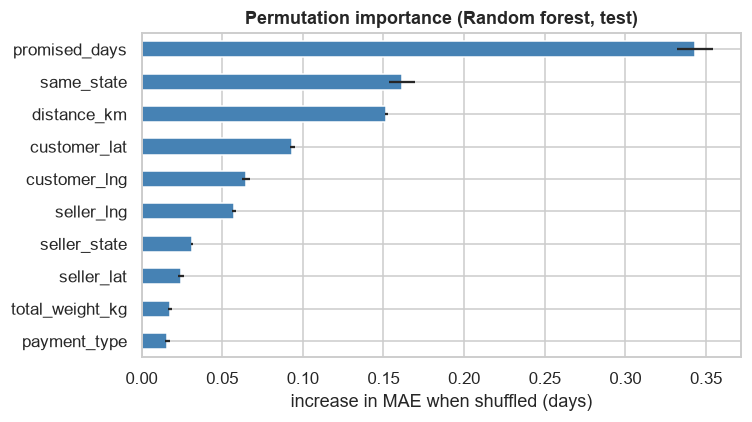

In [6]:
pi = permutation_importance(models[BEST], X_test, y_test, scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"MAE increase (days)": pi.importances_mean, "sd": pi.importances_std}, index=FEATURES).sort_values("MAE increase (days)", ascending=False)
display(imp.head(10))
fig, ax = plt.subplots(figsize=(7, 4))
imp.head(10)["MAE increase (days)"][::-1].plot.barh(xerr=imp.head(10)["sd"][::-1], ax=ax, color="steelblue")
ax.set(title=f"Permutation importance ({BEST}, test)", xlabel="increase in MAE when shuffled (days)")
plt.tight_layout(); plt.show()

**Interpretation.**
- **The promise is used most** (MAE +0.34 days when shuffled). It isn't an independent cause: Olist computes it from the route, so it summarises geography the model can't see directly.
- **Next:** whether customer and seller are in the **same state** (+0.16) and the **customer–seller distance** (+0.15), followed by customer and seller coordinates and the seller's state.
- **Basket, weight and payment features matter little.** Delivery time is mostly a matter of **route and logistics**, not of what is bought.

These importances describe what the model relies on, not causal effects. Model-specific explanations (SHAP) are left to the explainability phase.

## 5. From estimate to promise: a quantile model
A point estimate is right "on average", so promising it would make about half of all orders late. A **promise** needs a high quantile instead. A HistGradientBoosting model with **quantile loss (α = 0.95)** is fitted on development data with the selected model's tree settings. On the test period it's compared with Olist's promise on two things: **the share of orders delivered within the promise**, and **the average promise length**.

In [7]:
params = {k.split("__")[1]: v for k, v in models["HistGradientBoosting"].get_params().items()
          if k.startswith("histgradientboostingregressor__") and k.split("__")[1] in ("learning_rate", "max_leaf_nodes", "min_samples_leaf", "l2_regularization", "max_iter")}
q95 = make_pipeline(native_pre(), HistGradientBoostingRegressor(loss="quantile", quantile=0.95, categorical_features=CAT_IDX, random_state=SEED, **params))
q95.fit(X_dev, y_dev)
promise_ml = np.ceil(q95.predict(X_test))                          # whole days, like a promised date
actual_day = np.ceil(y_test)                                       # day-level comparison (D-08)
cmp = pd.DataFrame({
    "Olist promise": {"mean promise (days)": test["promised_days"].mean(), "median promise (days)": test["promised_days"].median(),
                      "share delivered within promise": float((actual_day <= test["promised_days"]).mean())},
    "ML P95 promise": {"mean promise (days)": promise_ml.mean(), "median promise (days)": float(np.median(promise_ml)),
                       "share delivered within promise": float((actual_day <= promise_ml).mean())}})
display(cmp)
print(f"Gold is_late in test (Olist promise): {test['is_late'].mean():.2%} late")
dev_cov = (np.ceil(y_dev) <= np.ceil(q95.predict(X_dev))).mean()
print(f"P95 model coverage on its own development data: {dev_cov:.1%} (nominal 95%)")

,Olist promise,ML P95 promise
mean promise (days),21.994,20.553
median promise (days),21.000,20.000
share delivered within promise,0.945,0.960


Gold is_late in test (Olist promise): 4.40% late


P95 model coverage on its own development data: 95.7% (nominal 95%)


**From estimate to promise: interpretation.**
- **On the test period, the P95 quantile model would have:**
  - promised **20.6 days on average**, against Olist's **22.0**, which is **about 1.4 days shorter**;
  - delivered **96.0%** of orders within its promise, against **94.5%** under Olist's promise (Gold `is_late`: 4.40% late).
- **Calibration:** on its own development data the model met its promise 95.7% of the time, close to the nominal 95%.
- **Business implications:**
  - Customers would get a **shorter and more reliable** promise at the same time. Shorter promises can raise conversion, and fewer missed promises protect reviews, since lateness is the strongest driver of 1–2 star reviews (Phase 8).
  - The quantile level is a business lever: a lower level shortens promises further and accepts more lateness; a higher level does the reverse. It should be chosen with the business, ideally tested in a **randomised experiment** (Phase 8 shows how to size one).
- **Caution:** the comparison covers one four-month test period with strong drift. Coverage must be monitored and the model retrained as delivery performance changes.

## 6. Summary

| Item | Result |
|---|---|
| Problem | Predict actual delivery time (days) at checkout, using leakage-checked features known at that moment |
| Validation | temporal test 2018-05 to 2018-08 (25,352 orders); `TimeSeriesSplit` CV on 2017-01 to 2018-04 (70,851 orders); preprocessing inside pipelines; seed 42 |
| Selected model (by CV) | random forest: CV MAE 5.38, **test MAE 4.37 days** (RMSE 5.92, R² 0.19) |
| Baselines | development median: test MAE 5.28 (the model cuts MAE by 17%); Olist's promise as an estimate: MAE 13.2 (a padded commitment, not an estimate) |
| Other models | HistGradientBoosting 4.22 (tied on CV, not selected); decision tree 4.41; linear regression 5.15 |
| Main predictors | promised days, same-state flag, customer–seller distance, coordinates |
| Business result | a P95 quantile promise is **about 1.4 days shorter** than Olist's on average (20.6 vs 22.0) **and more reliable** (96.0% vs 94.5% delivered within the promise) |

**Limitations:**
- **Population:** orders delivered with a date (D-06). Undelivered and canceled orders have no target.
- **Drift and errors:** delivery times shifted strongly over time, so the model over-predicts in the latest months, and very slow deliveries are systematically under-predicted. Production use would need periodic retraining and monitoring.
- **Features:** coordinates are zip-code centroids, and there are no seller-history or carrier features, which a later prediction moment could add.
- **Scope of the evaluation:** the quantile-promise result comes from one test period; an experiment should confirm it before a business change.
- **Interpretation:** importances aren't causal effects.